In [2]:
# Check well rates
from pathlib import Path
from IORlib.ECL import IX_input, UNRST_file
from IORlib.Flow import Flow, unrstfile
import numpy as np

from IORlib.utils import flatten

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = cop/'input/Model_From_IXF/Model_From_IXF'

#ix = IX_input(root)
#wellpos = ix.wellpos(*ix.wells_by_type()['WATER_INJECTOR'])
#inj_well = np.zeros(ix.dim(), dtype=bool)
#inj_well[*zip(*flatten(wellpos))] = True
#inj_conc = np.zeros(ix.dim())
#inj_conc[*zip(*wellhead)] = 1.0
#np.max(inj_conc)
#from IORlib.ECL import RFT_file, UNRST_file

unrst = unrstfile(root)
next(unrst.section_blocks())
unrst.end_step()
#unrst.dim()
#unrst.end_step()
#rft = RFT_file(root)

#flow = Flow(root)
#next(flow.wells())
#for well in flow.wells():
#    rate = flow.wellrate(well)
#    if np.max(rate.rate_in) > 0:
#        print(well[0].time, well[0].name, np.max(rate.rate_in), np.max(rate.rate_out))
#flow.nnc.get_rate(0)

# _read_data SEQNUM ([0, 1],) (1750,)
# data SEQNUM ([0, 1],) ((1750,),)
# blockdata {'SEQNUM_0': (1750,)}
# read 1750

np.int32(411)

In [8]:
A = np.arange(5*5*5*3).reshape(5, 5, 5, 3)
B = np.arange(5*5*5*7).reshape(5, 5, 5, 7)
AB = np.empty(3)
AB[:] = A[0,0,0,:] * B[0,0,0,6]
AB[:] += A[0,0,0,:] * B[0,0,0,6]
AB[:] = 0
AB

array([0., 0., 0.])

In [5]:
import numpy as np
x, y, z = 210, 250, 30
A = np.arange(x*y*z).reshape(x, y, z)

%timeit S1 = np.sum(A, axis=(0,1,2))
%timeit S2 = np.reshape(A, -1).sum()
#print(S1, S2)


493 µs ± 47.9 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
566 µs ± 147 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [ ]:
from pathlib import Path
from colorama import init
import numpy as np
#from IORlib.ECL import Flow, IX_input
#from IORlib.GSG import read_prop_file
from IORlib.Flow import Flow

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = cop/'input/Model_From_IXF/Model_From_IXF'

flow = Flow(root, res_block=True)
dim = flow.unrst.dim()

# Input Ekofisk
cl = np.zeros(dim)
# Tor
cl[:,:,14:] = 3.33
# Ekofisk
cl[:,:,:14] = 1.42
# Seawater
inlet = (0.56,)
name = ('CL',)
init = (cl,)
#tor = np.zeros(dim)
#tor[:,:,14:] = 1
#eko = np.zeros(dim)
#eko[:,:,:14] = 1
#wi = np.zeros(dim)
#name = ('TOR', 'EKO', 'WI')
#init = (tor, eko, wi)
#inlet = (0, 0, 1)

# # Input simple model
# name = ('WI',)
# init = (np.zeros(dim),)
# inlet = (1,)

#tracer_func = flow.tracer_explicit
tracer_func = flow.tracer_implicit
tracer = tracer_func(name, init, inlet, force_vol_balance=False)

# Step through time
stop = None
n = 0
n_write = 0
report_time = 1e-3
for trc in tracer:
    n += 1
    print(trc)
    print('   ' + trc.limits())    
    if report_time and int(trc.time/report_time) > n_write:
        file = trc.to_unrst()
        n_write += 1
        print(f'   Data written to {file}')
    else:
        trc.to_unrst()        
    if n == stop:
        break
   


-- step:    1, time:     0.010 days, dt:  0.010 days, cycles: 1
   CL: (1.420, 3.330)
Creating new UNRST-file: IORSIM_BASECASE_INPUT_tracer.UNRST
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:    2, time:     0.040 days, dt:  0.030 days, cycles: 1
   CL: (1.420, 3.331)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:    3, time:     0.130 days, dt:  0.090 days, cycles: 1
   CL: (1.419, 3.331)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:    4, time:     0.400 days, dt:  0.270 days, cycles: 1
   CL: (1.418, 3.331)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:    5, time:     1.210 days, dt:  0.810 days, cycles: 1
   CL: (1.417, 3.331)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:    6, time:     3.640 days, dt:  2.430 days, cycles: 1
   CL: (1.415, 3.332)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:    7, time:    10.930 days, dt:  7.290 days, cycles: 5
   CL: (1.413, 3.338)
   Data writte

/home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI/IORlib/Flow.py:399: RuntimeWarning: invalid value encountered in multiply
  prod_mass = rate.dt * rate.rate_out[..., 6][..., None] * conc


-- step:  116, time:   305.000 days, dt:  5.064 days, cycles: 1
   CL: (1.158, inf)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:  117, time:   305.175 days, dt:  0.175 days, cycles: 1
   CL: (nan, nan)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:  118, time:   305.236 days, dt:  0.060 days, cycles: 1
   CL: (nan, nan)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:  119, time:   305.416 days, dt:  0.180 days, cycles: 1
   CL: (nan, nan)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:  120, time:   305.957 days, dt:  0.541 days, cycles: 1
   CL: (nan, nan)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:  121, time:   307.580 days, dt:  1.623 days, cycles: 1
   CL: (nan, nan)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:  122, time:   312.448 days, dt:  4.868 days, cycles: 1
   CL: (nan, nan)
   Data written to IORSIM_BASECASE_INPUT_tracer.UNRST
-- step:  123, time:   322.448 days, dt: 10.00

Py
min = 1.3907e+00 (112, 109, 12)
max = 3.3413e+00 (93, 78, 14)
IX
min = 9.8465e-01 (91, 101, 13)
max = 3.3413e+00 (93, 78, 14)


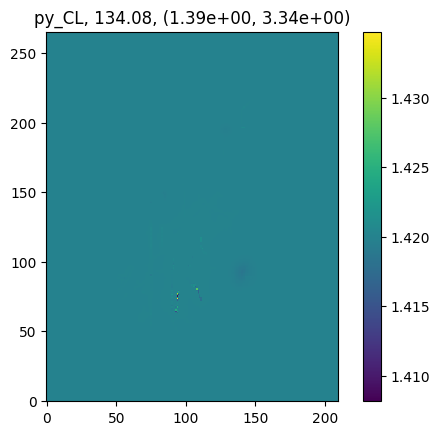

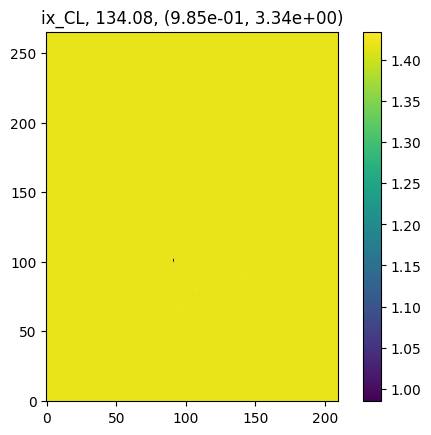

In [4]:
from itertools import islice
from os import times
from pathlib import Path
import numpy as np
import matplotlib.pyplot as pl
#from IORlib.ECL import Flow, IX_input
#from IORlib.GSG import read_prop_file
from IORlib.ECL import UNRST_file
from ior2ecl import Output
from IORlib.Flow import Flow, unrstfile

def imshow(data, title=None, rotate=True, save=''):
    if rotate:
        origin = 'lower'
        orientation = 'vertical'
    else:
        origin = 'upper'
        orientation = 'horizontal'
    pl.figure()
    pl.title(title)
    pl.imshow(data.T, origin=origin, aspect=1, interpolation='none')
    pl.colorbar(orientation=orientation)
    if save:
        pl.savefig('plots/' + save + '.png')

def min_max_3d(data):
    low = np.unravel_index(np.argmin(data), data.shape)
    high = np.unravel_index(np.argmax(data), data.shape)
    return data[low], data[high], *[tuple(map(int, v)) for v in (low, high)]

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = cop/'input/Model_From_IXF/Model_From_IXF'
#name = ('TOR', 'EKO', 'WI')
name = ('CL',)

pl.close('all')

# Compare tracer simulations
out = Output(root)

start = 50

# Intersect
ix_data = out.slb_unrst.blockdata('DOUBHEAD', 0, *[f'TR{n}' for n in name], start=start)    
ix_time, *ix_trc = next(ix_data)

# PyIOR
py_unrst = unrstfile(root)
#steps = tuple(py_unrst.steps())
#days = tuple(py_unrst.days())
#ind = next(i for i,d in enumerate(days) if d >= ix_time) - 1
#tart = steps[ind]
py_data = py_unrst.blockdata('DOUBHEAD', 0, *name, start=start)
py_time, *py_trc = next(py_data)


# IORSim
#ior_data = out.ior_unrst.blockdata('DOUBHEAD', 0, *name, start=start)
#ior_time, *ior_trc = next(ior_data)


cut = (slice(None), slice(None), 13)
#cut = (50, slice(None), slice(None))

py = dict(zip(name, py_unrst.reshape_dim(*py_trc)))
#ior = dict(zip(name, out.ior_unrst.reshape_dim(*ior_trc)))
ix = dict(zip(name, out.slb_unrst.reshape_dim(*ix_trc)))

var = 'CL' #'WI'
#print(py_time, ix_time, ior_time)

# Py
l, h, il, ih = min_max_3d(py[var])
print('Py')
print(f'min = {l:.4e} {il}')
print(f'max = {h:.4e} {ih}')
imshow(py[var][cut], f'py_{var}, {py_time:.2f}, ({l:.2e}, {h:.2e})')

# IX
l, h, il, ih = min_max_3d(ix[var])
print('IX')
print(f'min = {l:.4e} {il}')
print(f'max = {h:.4e} {ih}')
imshow(ix[var][cut], f'ix_{var}, {ix_time:.2f}, ({l:.2e}, {h:.2e})')

# IORSim
#l, h, il, ih = min_max_3d(ior[var])
#imshow(ior[var][cut], f'ior_{var}, {ior_time:.2f}, ({l:.2e}, {h:.2e})')

# Diff pyior - ix
#diff = py[var] - ix[var]
#max_pos = np.unravel_index(np.argmax(np.abs(diff)), diff.shape)
#print('py: max diff', max_pos, diff[max_pos])
#imshow(diff[cut], f'py_{var} - ix_{var}, {ix_time:.2f}, ({np.max(np.abs(diff)):.2e})')

# Diff ior - ix
#diff = ior[var] - ix[var]
#max_pos = np.unravel_index(np.argmax(np.abs(diff)), diff.shape)
#print('ior: max diff', max_pos, diff[max_pos])
#imshow(diff[cut], f'ior_{var} - ix_{var}, {ior_time:.2f}, ({np.max(np.abs(diff)):.2e})')


In [ ]:
from IORlib.ECL import UNRST_file


unrst = UNRST_file(unrstfile(root))
tuple(unrst.steps())

In [ ]:
from pathlib import Path
import numpy as np
from collections import defaultdict
from IORlib.Flow import Flow, Sort

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = cop/'input/Model_From_IXF/Model_From_IXF'

flow = Flow(root, res_block=True)
rate = next(flow.rates())
nnc_rate = flow.nnc.get_rate(flow.seqnum)
seq = flow.sort.topological(rate.rate_out[..., :6], nnc_rate, check=True)
#seq = flow.sort.topological(rate, nnc_rate, check=True)


In [ ]:
from pathlib import Path
import numpy as np
from IORlib.Flow import Flow

cop = Path.home() / 'CoP_files'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = cop/'input/Model_From_IXF/Model_From_IXF'

flow = Flow(root, res_block=True)

# Input Ekofisk
tor = np.zeros(flow.dim)
tor[:,:,14:] = 1
eko = np.zeros(flow.dim)
eko[:,:,:14] = 1
wi = np.zeros(flow.dim)
name = ('TOR', 'EKO', 'WI')
init = (tor, eko, wi)
inlet = (0, 0, 1)

for trc in flow.tracer_implicit(name, init, inlet, force_vol_balance=False):
    print(trc)#f'-- Step {trc.step}, time: {trc.time} days')


In [ ]:
from itertools import islice
indices = flow.nnc.indices
nnc_seq_gen = (i for i, s in enumerate(seq) if indices[0,*s][1]>0)
nnc_seq = list(islice(nnc_seq_gen, 0, None))
pos = {tuple(s):i for i,s in enumerate(seq)}

In [ ]:
n = 500000
#ijk = seq[nnc_seq[n]]
ijk = seq[n]
nnc_ind = flow.nnc.indices[:, *ijk]
nnc_pos1 = flow.nnc.pos[0, nnc_ind[0,0]:nnc_ind[0,1]]
nnc_pos2 = flow.nnc.pos[1, nnc_ind[1,0]:nnc_ind[1,1]]
nnc_blocks = flow.nnc.nnc
a = tuple(ijk.tolist())
b = [tuple(nnc_blocks[1, p].tolist()) for p in nnc_pos1]
c = [tuple(nnc_blocks[0, p].tolist()) for p in nnc_pos2]
print('ijk:', a, pos[a], 'pos1:', *b, pos[b[0]] if b else None, 'pos2:', *c, pos[c[0]] if c else None)
#print('ijk:', a, 'pos1:', *b, 'pos2:', *c)

flat = flow.sort.to_flat([ijk])[0]
adj = flow.sort.adj
a, b = adj.indptr[flat], adj.indptr[flat+1]
nb_ijk = flow.sort.to_coords(adj.indices[a:b]).tolist()
nb_pos = [pos[tuple(n)] for n in nb_ijk]
print('ijk:',ijk, pos[tuple(ijk)], list(zip(nb_ijk, nb_pos)))
#print(adj.data[a:b].tolist())

in_deg = np.array(adj.sum(axis=0), dtype=np.int32).ravel()
print('in_deg:', in_deg[flat])
#np.sum(in_deg > 0)
#print(f1, adj.indices[a:b], adj.data[a:b])
#print(ijk, flow.sort.to_coords(adj.indices[a:b]))
#in_counts = np.bincount(flow.sort.nb_targets, minlength=flow.sort.N)
#out_counts = np.bincount(flow.sort.nb_sources, minlength=flow.sort.N)
#print(in_counts[f1], out_counts[f1])
#n_deg[245878]
#[(i,oc) for i,f in enumerate(flat_seq) if (oc:=out_counts[f]) > 6]
#f2 = flow.sort.adj.indices[f1]
#ijk, flow.sort.to_coords([f2])
#adj[0].nonzero()

# ijk: (38, 69, 4) 3322 pos1: (38, 70, 5) 1200355 pos2: None
# ijk: [38 69  4] 3322 [([37, 69, 4], 1181728), ([38, 68, 4], 1201644), ([38, 69, 3], 1204139), ([38, 69, 5], 1199062), ([38, 70, 4], 1201645), ([38, 70, 5], 1200355), ([39, 69, 4], 1207708)]

In [ ]:
pos = np.array((39, 49, 7), dtype=np.int32)
pos = (56, 33, 21)
nnc = flow.nnc
for s in seq:
    i, j, k = s
    nnc_ind = nnc.indices[:, i, j, k]
    nnc_pos1 = nnc.pos[0, nnc_ind[0, 0]:nnc_ind[0, 1]]
    nnc_pos2 = nnc.pos[0, nnc_ind[1, 0]:nnc_ind[1, 1]]
    #print(nnc_pos1, nnc_pos2)
    s = 0
    for m in nnc_pos1:
        ii, jj, kk = nnc.nnc[0, m]
        print(ii, jj, kk)
        s += nnc_rate.rate_in[m]
#nnc = flow.nnc.nnc
#map = [Map(n, flow.dim) for n in nnc]
#nnc_keys = np.stack([m.keys for m in map])
#nnc_values = np.stack([m.values for m in map])
#k = nnc_keys[:, *pos]
#link1 = nnc_values[0, k[0, 0]:k[0, 1]]
#link2 = nnc_values[1, k[1, 0]:k[1, 1]]
#print(nnc[:, link1], 'in:', nnc_rate.rate_in[link1], 'out:', nnc_rate.rate_out[link1])
#print(nnc[:, link2], 'in:', nnc_rate.rate_in[link2], 'out:', nnc_rate.rate_out[link2])
#nnc[1, map[0][seq[0]]]
#m = map1[pos]
#m, flow.nnc.nnc[:, m]
#a = flow.nnc.map12[tuple(pos)][0]
#csum = np.cumsum([0] + [len(v) for v in flow.nnc.map12.values()])
#idx = np.stack((csum[:-1], csum[1:]), axis=-1)
#keys = dict(zip(flow.nnc.map12.keys(), idx))
#vals = np.array(list(flatten(flow.nnc.map12.values())))
#i = keys[tuple(pos)]
#pos, i, vals[i[0]:i[1]], [flow.nnc.nnc[:, v[3]] for v in vals[i[0]:i[1]]]

In [ ]:
link1

In [ ]:
nnc12[932610:932630]
#flow.nnc.map12[tuple(a[0][1])]

In [ ]:
#map = defaultdict(list)
#for idx, (s, d) in enumerate(zip(nnc[0], nnc[1])):
#    map[tuple(s)].append((d, idx))
pos = (39, 49, 7)
l1 = flow.nnc.map12[pos]
l2 = flow.nnc.map21[pos]
l1[0][1]

In [ ]:
nnc[0,:,0]

In [ ]:
map12 = mapping_simple(nnc[0])
map21 = mapping_simple(nnc[1])

In [ ]:
map12.get((56, 33, 21))

In [ ]:
map.get_from(56, 33, 21)


In [ ]:
map.get_to(55, 33, 20)

In [ ]:
pos = np.array([56, 33, 21])
start, end = map.rate_index_from[*pos]
list(zip(map.get_from(*pos), map.rate_in[start:end]))

In [ ]:
start, end = map.rate_index_from[*pos]
list(zip(map.get_to(*pos), map.rate_out[start:end]))

In [ ]:
nnc[0, 68], nnc[1, 68], nnc_rate.rate_in[68], nnc_rate.rate_out[68]

In [ ]:
flow.nnc.nnc

In [ ]:
nnc[0,:20]
#pos = np.array(nnc[0,0])
#matches = np.where((nnc[0] == pos).all(axis=1))[0]
#matches


In [ ]:
from pathlib import Path
import numpy as np
from IORlib.ECL import Flow

cop = Path.home() / 'CoP_files'
#root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
root = cop/'input/Model_From_IXF/Model_From_IXF'

flow = Flow(root)

# Input simple model
name = ('WI',)
init = (np.zeros(flow.unrst.dim()),)
inlet = (1,)
vbal = True

tracer = flow.tracer_implicit(name, init, inlet, force_vol_balance=vbal)
trc = next(tracer)


In [ ]:
rate = next(flow.rates())
b = (11, 11, )
iconn = tuple(zip(*(i for i in in_conn[b] if i[0] >= 0)))
rate.inflow[iconn].shape

In [ ]:
#rate.inflow[...,:6, None].shape, flow.connection_index().shape
inflow_conn = np.concatenate((rate.inflow[..., :6, None], flow.neighbour_connections()), axis=-1, dtype=object)
rates, ind = zip(*((rate, ind) for rate, *ind in inflow_conn[b] if rate > 0))

In [ ]:
import numpy as np
A = np.arange(6)
C = np.ones((20, 20, 5, 3))
b = (10, 10, 3)
D = np.stack([a * C[*b, :] for a in A])
np.sum(D, axis=0)

In [ ]:
from math import prod
from pathlib import Path
from itertools import islice
import matplotlib.pyplot as pl
import numpy as np
from IORlib.ECL import INIT_file, Flow, RFT_file, UNRST_file, IX_input
from IORlib.utils import flatten

%matplotlib widget

def imshow(data, title=None, rotate=True, save=''):
    if rotate:
        origin = 'lower'
        orientation = 'vertical'
        aspect = 'equal'
    else:
        origin = 'upper'
        orientation = 'horizontal'
        aspect = 5
    pl.figure()
    pl.title(title)
    pl.imshow(data.T, origin=origin, aspect=aspect, interpolation='none')
    pl.colorbar(orientation=orientation)
    if save:
        pl.savefig('plots/' + save + '.png')

cop = Path.home() / 'CoP_files'
root = cop/'input/Model_From_IXF/Model_From_IXF'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

#cut = (slice(100,None), slice(0, 100), 3)
cut = (slice(None), slice(None), 2)
#cut = (40, slice(None), slice(None))
start, stop, step = 0, None, 1

ix = IX_input(root)
dim = ix.dim()
wells = ix.wells_by_type()
wellpos = {k:tuple(zip(*flatten(ix.wellpos(*v)))) for k, v in wells.items()}
mask_none = np.ones(dim, dtype=bool) 
print(np.sum(mask_none))
# Exclude all water-injection blocks
mask_winj = np.ones(dim, dtype=bool)
mask_winj[wellpos['WATER_INJECTOR']] = False
print(np.sum(mask_winj))
# Exclude all gas-injection blocks
mask_ginj = np.ones(dim, dtype=bool)
mask_ginj[wellpos['GAS_INJECTOR']] = False
print(np.sum(mask_ginj))
# Exclude all production blocks
mask_prod = np.ones(dim, dtype=bool)
mask_prod[wellpos['PRODUCER']] = False
# Exclude all well-blocks (bitwise & faster than multiplication)
mask_wells = mask_winj & mask_ginj & mask_prod
print(np.sum(mask_wells))

names = ('WI', 'TOR', 'EKO')
days = []
low  = {'WI':[], 'TOR':[], 'EKO':[]}
high = {'WI':[], 'TOR':[], 'EKO':[]}
count_all      = {'mask':mask_none,  'WI':[], 'TOR':[], 'EKO':[]}
count_no_wells = {'mask':mask_wells, 'WI':[], 'TOR':[], 'EKO':[]}
count_no_winj  = {'mask':mask_winj,  'WI':[], 'TOR':[], 'EKO':[]}
count_no_ginj  = {'mask':mask_ginj,  'WI':[], 'TOR':[], 'EKO':[]}
count_no_prod  = {'mask':mask_prod,  'WI':[], 'TOR':[], 'EKO':[]}
count = {'all':count_all, 'no_wells':count_no_wells, 'no_winj':count_no_winj, 'no_ginj':count_no_ginj, 'no_prod':count_no_prod}

unrst = UNRST_file(root)
end = unrst.end_step()
keys = ('DOUBHEAD', 0, 'TRWI', 'TRTOR', 'TREKO')
n = 0
limits = (0.01, 0.1, 1, 10)
for time, *data in unrst.blockdata(*keys, start=start, stop=stop, step=step):
    #for trc, name in zip(data, names):
    for trc, name in zip(unrst.reshape_dim(*data), names):
        #trc[65, 63, 2] = 1
        trc = np.array(trc)
        low[name].append(np.min(trc))
        high[name].append(np.max(trc))
        for key, val in count.items():
            masked = trc[val['mask']]
            above = masked[masked > 1] - 1
            sums = [np.sum(above >= l) for l in limits]
            val[name].append(sums)
    days.append(time)
    n += 1
    print(f'\r {n: 3}/{end+1}', end='')
        #print(np.argwhere(trc == high))
        #imshow(trc[cut], f'{name}, {time:.2f}, ({low:.2e}, {high:.2e})')
        #conc[name] = trc
print()
# flow = Flow(root, res_block=False)
# #vol = next(islice(flow.volume(), 0, None))
# data = next(islice(flow.data(), start, stop, step))
# #imshow(data.dbw[cut], f'dbw, {data.time:.2f}')
# #imshow(data.rs[cut], f'rs, {data.time:.2f}')
# print(data.time)
# #imshow(data.dbw[cut], f'dbw, {data.time:.2f}')
# #imshow(data.dP[cut], f'dP, {data.time:.2f}')
# #imshow(data.dS[cut], f'dS, {data.time:.2f}')
# #imshow(data.dS_flow[cut], f'dS_flow, {data.time:.2f}')
# imshow(data.dVp[cut], f'dVp, {data.time:.2f}')
# #imshow((data.dV_flow + data.dVp)[cut], f'dV_flow, {data.time:.2f}')
# #diff = data.dV - data.dV_flow
# #max_diff = np.max(np.abs(diff))
# #imshow(diff[cut], f'dV - dV_flow, {data.time:.2f}, ({max_diff:.2e})')

In [ ]:
pl.close('all')
pl.figure(1)
pl.title('High')
# pl.figure(2)
# pl.title('Count')
# pl.figure(3)
# pl.title('Percentiles')
years = 1971 + np.array(days)/365
count_figs = []
for name in names:
    pl.figure(1)
    pl.plot(years, high[name], label=name)
    val = count['all']
    f = pl.figure()
    count_figs.append((f, f'{name}_all'))
    pl.title(name + ', all')
    for i, lim in enumerate(limits):
        pl.semilogy(years, np.array(val[name])[:,i], label=f'{lim}')
    pl.legend()
    for key in list(count.keys())[1:]:
        val = count[key]
        f = pl.figure()
        count_figs.append((f, f'{name}_all-{key}'))
        pl.title(name + ', all - ' + key)
        diff = np.array(count['all'][name]) - np.array(val[name])
        for i, lim in enumerate(limits):
            pl.semilogy(years, diff[:,i], label=f'{lim}')
        pl.legend()
pl.figure(1)
pl.legend()
pl.xlabel('Years')
pl.ylabel('Concentration')
pl.savefig('plots/high.pdf')
for fig, name in count_figs:
    pl.figure(fig.number)
    pl.xlabel('Years')
    pl.ylabel('Block count')
    pl.legend()
    pl.savefig(f'plots/{name}.pdf')

In [ ]:
from collections import defaultdict
from IORlib.ECL import IX_input
ix = IX_input(root)
wells = defaultdict(list)
for wname, wtype in ix.wells():
    wells[wtype].append(wname)
dict(wells)

In [ ]:
from IORlib.ECL import IX_input

cell = (65, 63, 2)
cell = (83, 58, 2)
ix = IX_input(root)
name, kind, bbox = zip(*ix.wells_near_cells(cell))
name
#[[slice(*b) for b in bb] for bb in bbox ]
#cut = (65, slice(None), slice(None))
#imshow(conc['EKO'][cut], f'EKO, {time:.2f}', rotate=False)

In [ ]:
cells = ((65, 63, 2),)
[(w,k) for w, k, bb in zip(wells, kind, wellbbox) if any_cell_in_box(cells, bb)]


In [ ]:
pos = wellpos[0]
[(p[0], p[-1]) for p in map(sorted, zip(*pos))]

In [ ]:
#%matplotlib inline
wells = next(islice(flow.wells(), start, stop, step))
map = np.zeros(flow.unrst.dim(), dtype=int)
for well in wells:
    map[well.pos] = -1 if well.rate[0] < 0 else 1
map[flow.nnc_ijk[0]] = 2
map[flow.nnc_ijk[1]] = 3
imshow(map[cut], 'map')

In [ ]:
ind = [list(zip(*ijk)) for ijk in flow.nnc_ijk]
print(ind[0][31], ind[1][31])
neg = np.where(vol.nnc.rate < 0)[0]
ind[0][neg[0]], ind[1][neg[0]]

In [ ]:
init = INIT_file(root)
nnc = next(init.blockdata('NNC1', 'NNC2'))
b, c = [np.array(n) for n in nnc]
neg_nnc = np.where(c - b < 0)[0]

In [ ]:
b.shape

In [ ]:
init.cell_ijk(None)